# Study 9 with speaker β fixed at study 6's value: fitted parameters and linking-function components

Study 9 preregistered data, the **original** per-feature Beta-mixture linking function (not the ZOIB one).
Exact 0 and 100 ratings are moved half a slider bin inward, as the loader does. Speaker β is **fixed** at the
study-6 posterior median (≈28.9, from `results/study6-fit/`); ls, μ₀ and σ are fit to study 9. Reads the
fits in `results/study9-fit-fixed-beta/`: the full model (fitted length scale) and its distance-blind null
(length scale fixed at `LS_FLAT`), both with β pinned.

For feature j in condition c, a rating r is modeled as

    r ~ pz1[c, j] · Beta(a_kl[j], b_kl[j])  +  (1 − pz1[c, j]) · Beta(a_nkl[j], b_nkl[j])

Each feature has its own shapes, shared across conditions, and there are no point masses.
pz1 is the ratings-free GP coherence for that condition.

1. Posterior over θ = (ls, μ₀, σ); β is fixed
2. The two components of each feature, shown separately (as in section 5b of `zoib-linking-checks.ipynb`)
3. The same components, mixed with each condition's own coherence
4. Shape table

In [1]:
import os
os.environ.setdefault("JAX_ENABLE_X64", "1")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plot_style
plot_style.use_lexend()          # Lexend everywhere (DejaVu Sans fills in σ/β)
from matplotlib.lines import Line2D
from scipy.stats import beta as sbeta

import inference as inf

RESULTS_DIR = 'results/study9-fit-fixed-beta'
geom = inf.load_geometry()
responses_cond, _ = inf.load_responses('../../data/study9_prereg.csv')
CONDS = list(inf.CONDITIONS)                      # physical, diet, personality, heterogeneous
features, trait, J = geom['test_feature_names'], geom['test_trait'], geom['J']
R = {c: np.asarray(responses_cond[c]) for c in CONDS}   # exact 0/1 nudged half a bin inward
print({c: R[c].shape[0] for c in CONDS}, "participants per condition")

z = np.load(os.path.join(RESULTS_DIR, 'fitted-link-shapes.npz'), allow_pickle=True)
assert [str(f) for f in z['feature_names']] == list(features)
a_kl, b_kl, a_nkl, b_nkl = np.asarray(z['shapes']).T
m_kl, m_nkl = a_kl / (a_kl + b_kl), a_nkl / (a_nkl + b_nkl)
k_kl, k_nkl = a_kl + b_kl, a_nkl + b_nkl
LS, MU, SIG, BETA_SPK = [float(v) for v in z['theta']]
pz1 = {c: np.asarray(v) for c, v in inf.prior_pz1_modes(geom, LS, MU, SIG, beta_speaker=BETA_SPK).items()}
print(f"posterior median θ: ls={LS:.3f}  mu_0={MU:+.3f}  sigma={SIG:.3f}  speaker beta={BETA_SPK:.3f}")

COND_COLOR = {'physical': '#7b4bd6', 'diet': '#c2185b', 'personality': '#1baf7a', 'heterogeneous': '#eda100'}
CLS_COLOR = {'kl': '#2a78d6', 'nkl': '#eb6834'}
MIX_COLOR = '#eda100'
TEXT_1, TEXT_2, MUTED, GRID = '#0b0b0b', '#52514e', '#8a8984', '#e6e5e1'
plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': MUTED, 'axes.labelcolor': TEXT_2, 'xtick.color': TEXT_2, 'ytick.color': TEXT_2,
    'axes.titlesize': 10, 'axes.labelsize': 9, 'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.fontsize': 8, 'legend.frameon': False,
})
def grid_y(ax):
    ax.grid(axis='y', color=GRID, lw=0.6); ax.set_axisbelow(True)

{'physical': 99, 'diet': 98, 'personality': 103, 'heterogeneous': 101} participants per condition


posterior median θ: ls=1.824  mu_0=-0.231  sigma=0.286  speaker beta=28.948


## 1. Posterior over θ

Median and 95% interval of the VBMC posterior for the full model and the distance-blind null. β is pinned
in both (drawn as a vertical line).

full             ELBO=974.5  evals=250  probable  8 min
null (ls fixed)  ELBO=963.3  evals=275  probable  8 min


fit             full                 null (ls fixed)                
                2.5%   97.5%  median            2.5%   97.5%  median
parameter                                                           
length scale   0.764   3.346   1.824          10.000  10.000  10.000
μ₀            -0.388  -0.072  -0.231          -0.573  -0.071  -0.271
σ              0.246   0.332   0.286           0.222   0.373   0.286
speaker β     28.948  28.948  28.948          28.948  28.948  28.948

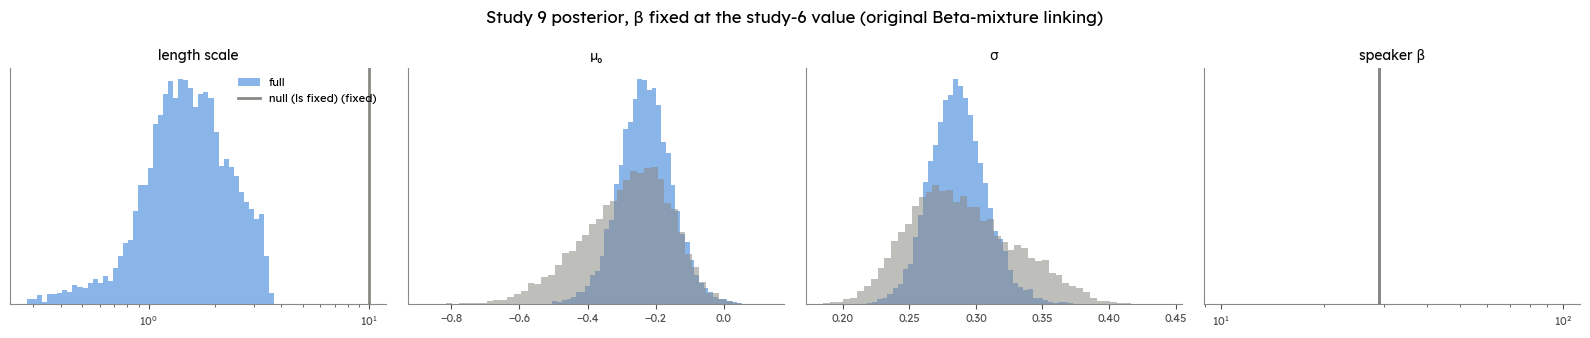

In [2]:
KEYS = [('length scale', 'ls_samples'), ('μ₀', 'mu0_samples'), ('σ', 'sigma_samples'), ('speaker β', 'beta_samples')]
FITS = {'full': 'fitted-feature-shapes.npz', 'null (ls fixed)': 'fitted-feature-shapes-null.npz'}
post, rows = {}, []
for name, fn in FITS.items():
    zz = np.load(os.path.join(RESULTS_DIR, fn), allow_pickle=True)
    meta = json.loads(str(zz['meta']))
    post[name] = {k: np.asarray(zz[k]) for _, k in KEYS}
    for lab, k in KEYS:
        s = post[name][k]
        rows.append({'fit': name, 'parameter': lab, 'median': np.median(s),
                     '2.5%': np.percentile(s, 2.5), '97.5%': np.percentile(s, 97.5)})
    print(f"{name:<16} ELBO={meta['elbo']:.1f}  evals={meta['func_count']}  "
          f"{meta['convergence_status']}  {meta['runtime_s'] / 60:.0f} min")
display(pd.DataFrame(rows).pivot_table(index='parameter', columns='fit', values=['median', '2.5%', '97.5%'],
                                       sort=False).swaplevel(axis=1).sort_index(axis=1, level=0).round(3))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, (lab, k) in zip(axes, KEYS):
    for name, col in zip(FITS, ['#2a78d6', MUTED]):
        s = post[name][k]
        if np.ptp(s) < 1e-9:                      # the null's pinned length scale
            ax.axvline(s[0], color=col, lw=2, label=f'{name} (fixed)')
            continue
        bins = np.geomspace(s.min(), s.max(), 50) if k in ('beta_samples', 'ls_samples') else 50
        ax.hist(s, bins=bins, density=True, color=col, alpha=0.55, label=name)
    if k in ('beta_samples', 'ls_samples'):
        ax.set_xscale('log')
    ax.set_title(lab, color=TEXT_1); ax.set_yticks([])
axes[0].legend(loc='upper right')
fig.suptitle('Study 9 posterior, β fixed at the study-6 value (original Beta-mixture linking)', fontsize=12)
fig.tight_layout(); plt.show()

## 2. The two components of each feature, separately

As in section 5b of `zoib-linking-checks.ipynb`, but for the original linking function. That function has
**no point masses**, so each component is just a Beta density and integrates to 1. There's no
(1 − P(0) − P(100)) scaling and no P(0)/P(100) text.
- **blue / orange curve**: kind-linked (kl) / not-kind-linked (nkl) component, Beta(a, b);
- **dashed line**: the component's mean m;
- **yellow**: the feature's final linking function, the two components mixed using coherence averaged
  over participants across the four conditions (the mixture is linear in coherence, so this equals the
  participant-weighted average of the four conditions' mixtures);
- **grey histogram**: the feature's pooled ratings (density), including the nudged 0s and 100s.

Components with a < 1 or b < 1 shoot up at the edge (U- or J-shaped). The y-axis is capped so the bulk of
the plot stays readable, and an arrow marks a component that runs off the top.

average coherence per feature: 0.56, 0.56, 0.56, 0.57, 0.56, 0.57, 0.57, 0.57, 0.57, 0.57, 0.57, 0.56, 0.57, 0.56, 0.57


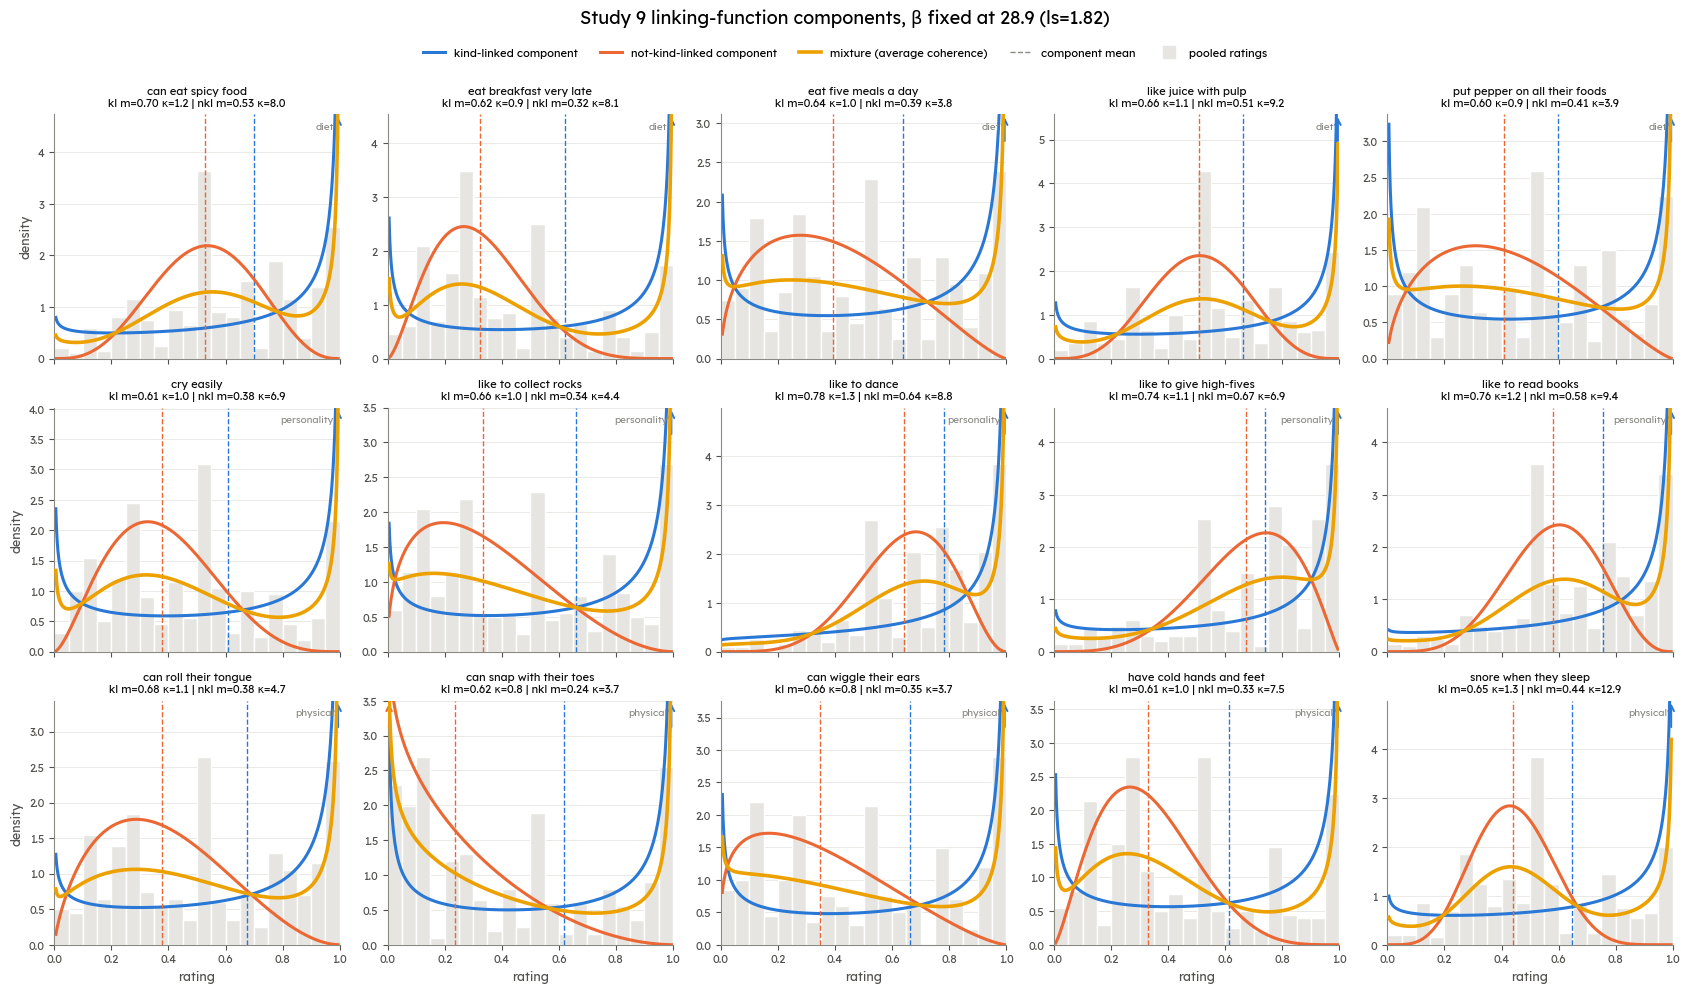

In [3]:
XG = np.linspace(0.005, 0.995, 400)
HBINS = np.linspace(0, 1, 21)
ORDER = [j for t in ['diet', 'personality', 'physical'] for j in range(J) if trait[j] == t]
n_c = np.array([R[c].shape[0] for c in CONDS], float)
pz1_bar = np.sum([n * pz1[c] for n, c in zip(n_c, CONDS)], axis=0) / n_c.sum()
Rall = np.concatenate([R[c] for c in CONDS])

def comp(j, c):
    a, b = (a_kl[j], b_kl[j]) if c == 'kl' else (a_nkl[j], b_nkl[j])
    return sbeta.pdf(XG, a, b)

def panel(ax, j, mixes, cc=CLS_COLOR, cls_ls='-', cls_lw=2.2):
    h = ax.hist(Rall[:, j], bins=HBINS, density=True, color=GRID, edgecolor='white')[0]
    body = [h.max()]
    for c in ('kl', 'nkl'):
        y = comp(j, c)
        ax.plot(XG, y, color=cc[c], lw=cls_lw, ls=cls_ls)
        ax.axvline(m_kl[j] if c == 'kl' else m_nkl[j], color=cc[c], lw=1, ls=':' if cls_ls == '--' else '--')
        body.append(y[40:-40].max())              # bulk height, ignoring the edge spikes
    for w, col, lw in mixes:
        y = w * comp(j, 'kl') + (1 - w) * comp(j, 'nkl')
        ax.plot(XG, y, color=col, lw=lw, zorder=4)
        body.append(y[40:-40].max())
    top = 1.3 * max(body)
    for c in ('kl', 'nkl'):
        y = comp(j, c)
        for x_e, y_e in [(XG[0], y[0]), (XG[-1], y[-1])]:
            if y_e > top:
                ax.annotate('', (x_e, top), xytext=(x_e, 0.88 * top),
                            arrowprops=dict(arrowstyle='->', color=cc[c], lw=1.4))
    ax.set_ylim(0, top); ax.set_xlim(0, 1); grid_y(ax)
    ax.set_title(f"{features[j]}\nkl m={m_kl[j]:.2f} κ={k_kl[j]:.1f} | nkl m={m_nkl[j]:.2f} κ={k_nkl[j]:.1f}",
                 fontsize=8, color=TEXT_1)

def grid_fig(mix_fn, extra_legend, title, cc=CLS_COLOR, cls_ls='-', cls_lw=2.2):
    nrow = int(np.ceil(J / 5))
    fig, axes = plt.subplots(nrow, 5, figsize=(17, 3.2 * nrow), sharex=True)
    for ax, j in zip(axes.ravel(), ORDER):
        panel(ax, j, mix_fn(j), cc, cls_ls, cls_lw)
        ax.text(0.98, 0.97, trait[j], transform=ax.transAxes, ha='right', va='top', fontsize=7, color=MUTED)
    for ax in axes.ravel()[J:]:
        ax.axis('off')
    for ax in axes[-1]:
        ax.set_xlabel('rating')
    for ax in axes[:, 0]:
        ax.set_ylabel('density')
    leg = [Line2D([], [], color=cc['kl'], lw=cls_lw, ls=cls_ls, label='kind-linked component'),
           Line2D([], [], color=cc['nkl'], lw=cls_lw, ls=cls_ls, label='not-kind-linked component')]
    leg += extra_legend
    leg += [Line2D([], [], color=MUTED, lw=1, ls=':' if cls_ls == '--' else '--', label='component mean'),
            Line2D([], [], marker='s', ls='', color=GRID, ms=9, label='pooled ratings')]
    fig.legend(handles=leg, loc='upper center', ncol=len(leg), bbox_to_anchor=(0.5, 1.0))
    fig.suptitle(title, y=1.03, fontsize=13)
    fig.tight_layout(); plt.show()

print("average coherence per feature: " + ", ".join(f"{v:.2f}" for v in pz1_bar[ORDER]))
grid_fig(lambda j: [(pz1_bar[j], MIX_COLOR, 2.6)],
         [Line2D([], [], color=MIX_COLOR, lw=2.6, label='mixture (average coherence)')],
         f"Study 9 linking-function components, β fixed at {BETA_SPK:.1f} (ls={LS:.2f})")

## 3. Mixed with each condition's own coherence

The same components, with one mixture per condition, each using that condition's own ratings-free pz1. In
study 9 the field is nearly flat, so expect the four condition mixtures to sit almost on top of each other. The components
are drawn as grey dashed lines here (dark = kl, light = nkl), so the condition colors stay distinct.

          physical   diet  personality  heterogeneous
pz1 min      0.562  0.561        0.563          0.565
pz1 mean     0.565  0.565        0.565          0.566
pz1 max      0.568  0.568        0.568          0.567


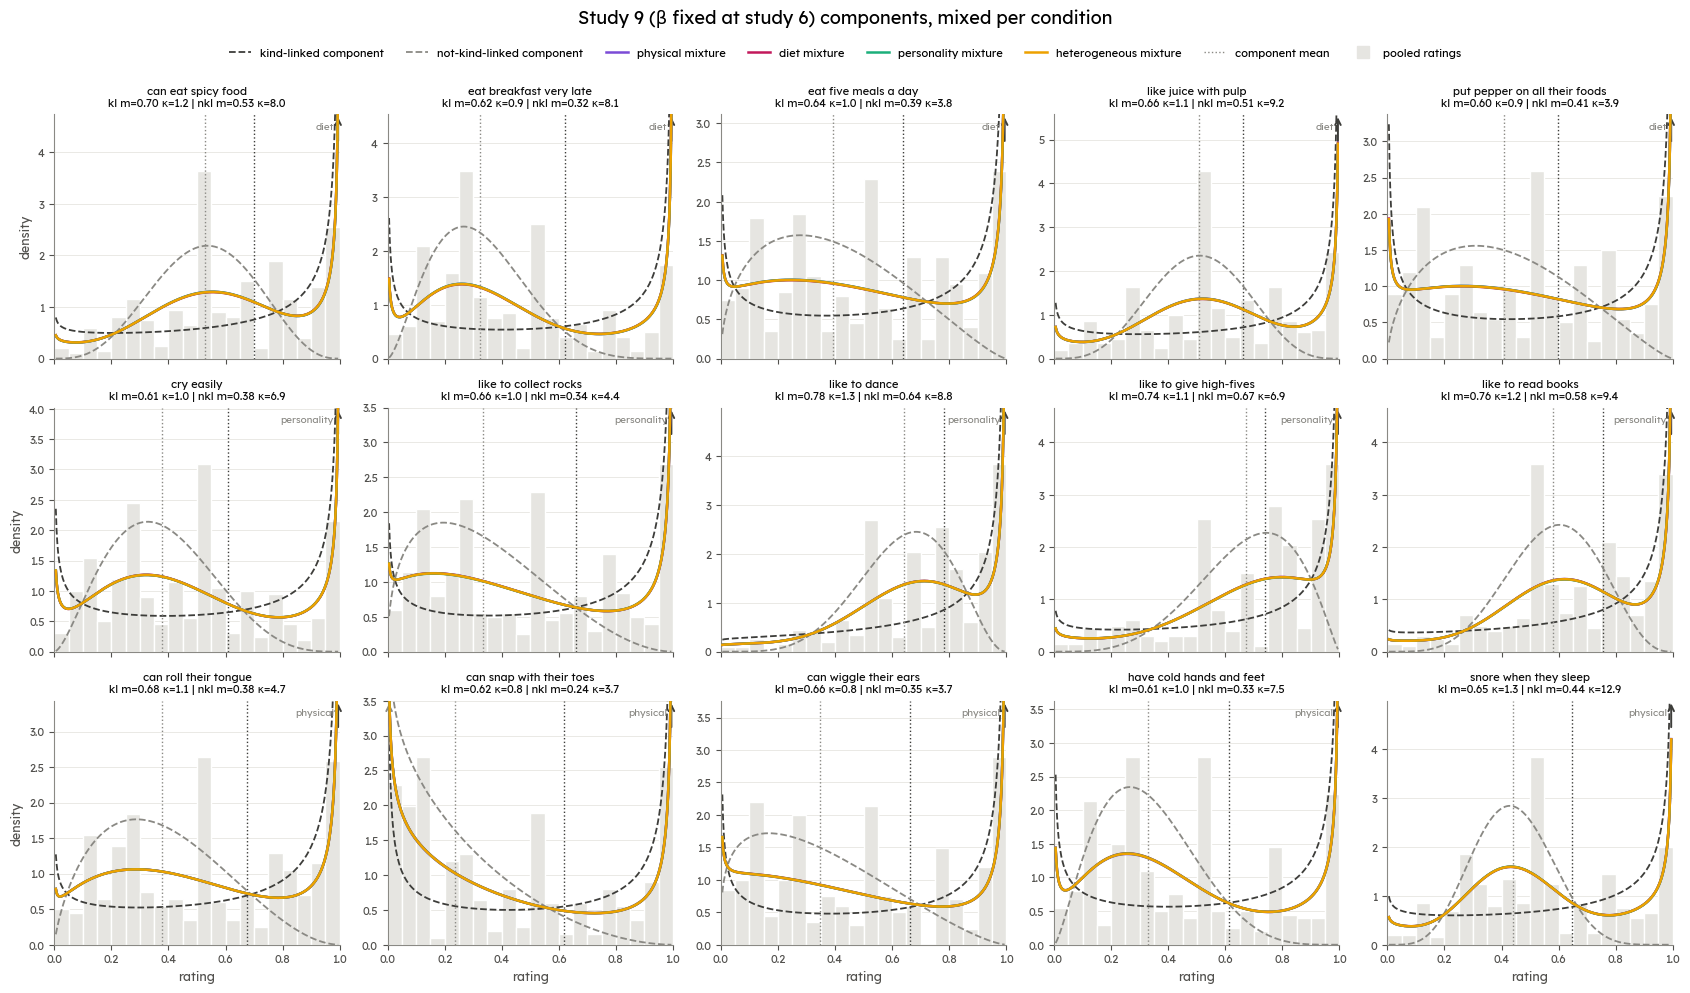

In [4]:
print(pd.DataFrame({c: [pz1[c].min(), pz1[c].mean(), pz1[c].max()] for c in CONDS},
                   index=['pz1 min', 'pz1 mean', 'pz1 max']).round(3))
grid_fig(lambda j: [(pz1[c][j], COND_COLOR[c], 1.8) for c in CONDS],
         [Line2D([], [], color=COND_COLOR[c], lw=1.8, label=f'{c} mixture') for c in CONDS],
         "Study 9 (β fixed at study 6) components, mixed per condition",
         cc={'kl': '#3d3d3a', 'nkl': MUTED}, cls_ls='--', cls_lw=1.3)

## 4. Shape table

In [5]:
pd.DataFrame({'feature': features, 'trait': trait,
              'a_kl': a_kl, 'b_kl': b_kl, 'm_kl': m_kl, 'κ_kl': k_kl,
              'a_nkl': a_nkl, 'b_nkl': b_nkl, 'm_nkl': m_nkl, 'κ_nkl': k_nkl,
              **{f'pz1 {c}': pz1[c] for c in CONDS}}).iloc[ORDER].round(3).reset_index(drop=True)

,feature,trait,a_kl,b_kl,m_kl,κ_kl,a_nkl,b_nkl,m_nkl,κ_nkl,pz1 physical,pz1 diet,pz1 personality,pz1 heterogeneous
0,can eat spicy food,diet,0.834,0.359,0.699,1.193,4.201,3.767,0.527,7.968,0.562,0.568,0.563,0.565
1,eat breakfast very late,diet,0.563,0.340,0.623,0.904,2.631,5.481,0.324,8.112,0.563,0.568,0.563,0.565
2,eat five meals a day,diet,0.621,0.352,0.638,0.973,1.508,2.316,0.394,3.823,0.562,0.568,0.563,0.565
3,like juice with pulp,diet,0.745,0.383,0.661,1.128,4.659,4.509,0.508,9.168,0.563,0.568,0.565,0.566
4,put pepper on all their foods,diet,0.519,0.350,0.597,0.869,1.587,2.307,0.408,3.894,0.562,0.568,0.563,0.565
5,cry easily,personality,0.614,0.394,0.609,1.008,2.611,4.314,0.377,6.924,0.566,0.565,0.568,0.567
6,like to collect rocks,personality,0.633,0.325,0.661,0.959,1.462,2.899,0.335,4.361,0.564,0.565,0.568,0.566
7,like to dance,personality,1.033,0.287,0.783,1.319,5.629,3.139,0.642,8.768,0.566,0.566,0.568,0.567
8,like to give high-fives,personality,0.790,0.281,0.738,1.071,4.660,2.262,0.673,6.923,0.564,0.565,0.568,0.566
9,like to read books,personality,0.936,0.302,0.756,1.238,5.443,3.922,0.581,9.365,0.564,0.565,0.568,0.566
